# 04 · Artifact và dự đoán local

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'pyproject.toml').exists():
    ROOT = ROOT.parent
if not (ROOT / 'pyproject.toml').exists():
    raise FileNotFoundError('Mở notebook từ thư mục dự án hoặc notebooks/.')
sys.path.insert(0, str(ROOT))
from scripts import final_study as study
from IPython.display import display
study.style()

In [2]:
forecasts = study.verify_inference()
display(forecasts)

,model,symbol,decision_time,prediction,reload_max_abs_diff,sha256,signal_approved,fresh_at_execution
0,ridge,BTCUSDT,2026-11-14 00:00:00+00:00,0.000332,0.0,b703949f23af23e5e663806ac4a076b1181ff316443b85...,False,False
1,ridge,ETHUSDT,2026-11-14 00:00:00+00:00,0.001040,0.0,b703949f23af23e5e663806ac4a076b1181ff316443b85...,False,False
2,xgboost_d3,BTCUSDT,2026-11-14 00:00:00+00:00,-0.001162,0.0,81d3423f9622986600e74b3ae7e156ad6fef336236de89...,False,False
3,xgboost_d3,ETHUSDT,2026-11-14 00:00:00+00:00,-0.000503,0.0,81d3423f9622986600e74b3ae7e156ad6fef336236de89...,False,False
4,tcn_fixed6,BTCUSDT,2026-11-14 00:00:00+00:00,0.000740,0.0,ba69aa4a0bf8d3340e01fd8838d5ef953d9650d2d57077...,False,False
5,tcn_fixed6,ETHUSDT,2026-11-14 00:00:00+00:00,0.000773,0.0,ba69aa4a0bf8d3340e01fd8838d5ef953d9650d2d57077...,False,False


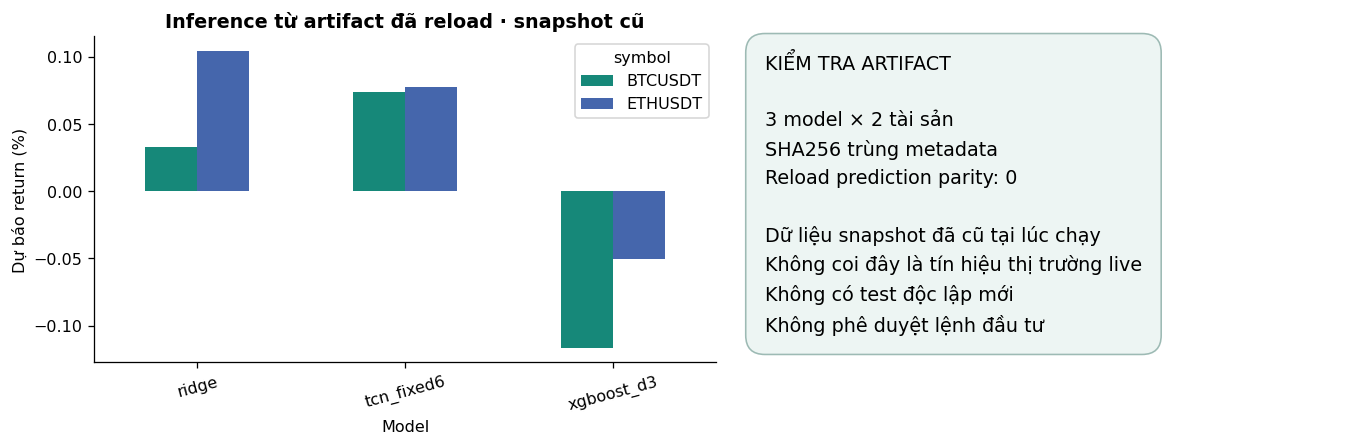

In [3]:
study.show(study.inference_chart(forecasts))

In [4]:
import os
os.environ['QUANTSTREAM_ROOT'] = str(study.WORK)
from streamlit.testing.v1 import AppTest
app = AppTest.from_file(str(ROOT / 'app.py'), default_timeout=40).run()
checked = []
for page in ['Thị trường','Dự báo','Kiểm định','Danh mục','Dữ liệu']:
    app.radio[0].set_value(page).run()
    if app.exception:
        raise RuntimeError([e.message for e in app.exception])
    checked.append({'page':page, 'runtime_exceptions':len(app.exception)})
display(__import__('pandas').DataFrame(checked))
print('AppTest kiểm tra runtime 5 trang; chưa phải ảnh chụp trình duyệt trên máy Windows.')

AppTest kiểm tra runtime 5 trang; chưa phải ảnh chụp trình duyệt trên máy Windows.


2026-11-21 07:21:04.877 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


,page,runtime_exceptions
0,Thị trường,0
1,Dự báo,0
2,Kiểm định,0
3,Danh mục,0
4,Dữ liệu,0


In [5]:
bundle = study.package()
display(bundle)
print('Giải nén vào thư mục mới; đặt QUANTSTREAM_ROOT để mở app bằng Ridge/XGBoost vừa train.')
print('TCN final refit dùng để inference nghiên cứu riêng, không gắn nhãn holdout sạch để import qua guard cũ.')

Giải nén vào thư mục mới; đặt QUANTSTREAM_ROOT để mở app bằng Ridge/XGBoost vừa train.
TCN final refit dùng để inference nghiên cứu riêng, không gắn nhãn holdout sạch để import qua guard cũ.


{'file': 'QuantStream_Research_Workspace.zip',
 'bytes': 8215321,
 'sha256': '4cf8eede585c18734ed660499845c851ee96f9a0d67c8344515b40670507d165',
 'usage': 'Extract to a NEW directory and set QUANTSTREAM_ROOT; see README.'}